# Regularization and Gradient Descent Exercises


# Obiectivele învățării

- Explicarea funcțiilor de cost, regularizarea, selectarea caracteristicilor și hiperparametrii
- Rezumarea algoritmilor de optimizare statistică complexă, cum ar fi coborârea gradientului și aplicarea sa la regresia liniară



## Introducere

Vom începe cu un scurt tutorial despre regresie, caracteristici polinomiale și regularizare, bazat pe un set de date foarte simplu, rar, care conține o coloană de date `x` și date zgomotoase asociate `y`. Fișierul de date se numește `X_Y_Sinusoid_Data.csv`. 

### Pregătire (Google Colab)
Sunt necesare fișierele `X_Y_Sinusoid_Data.csv` și `Ames_Housing_Sales.csv`.

In [1]:
import os
FILES = ['X_Y_Sinusoid_Data.csv', 'Ames_Housing_Sales.csv']
missing = [f for f in FILES if not os.path.exists(f)]
if missing:
    print('Încărcați fișierele:', missing)
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

RANDOM_STATE = 42

## Întrebare 1

* Importați datele. 

* De asemenea, generați aproximativ 100 de puncte de date x egal distanțate pe intervalul 0-1. Folosind aceste puncte, calculați datele y care reprezintă „adevărul de bază” (funcția reală) din ecuația: $y = sin(2\pi x)$

* Reprezentați grafic datele rarefiate (`x` vs `y`) și datele calculate („reale”).


(20, 2)


,x,y
0,0.038571,0.066391
1,0.166776,1.027483
2,0.183153,1.245302
3,0.187359,1.004781
4,0.243116,1.264121


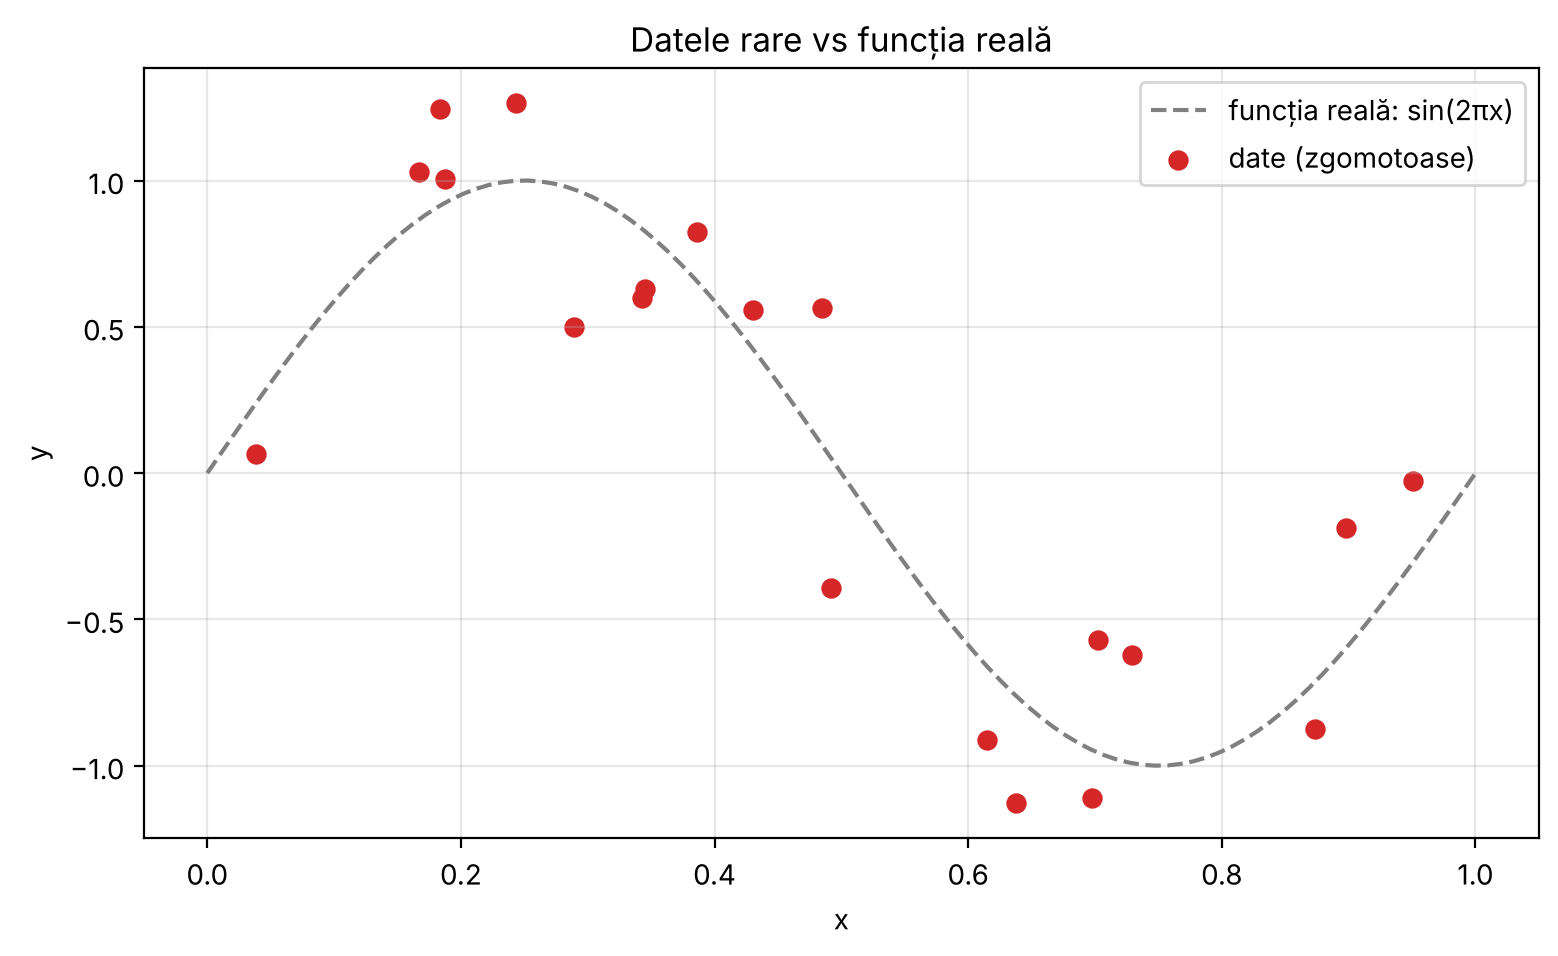

In [2]:
data = pd.read_csv('X_Y_Sinusoid_Data.csv')
print(data.shape); display(data.head())

X_real = np.linspace(0, 1.0, 100)
Y_real = np.sin(2 * np.pi * X_real)

plt.figure(figsize=(9, 5))
plt.plot(X_real, Y_real, ls='--', color='gray', label='funcția reală: sin(2πx)')
plt.scatter(data['x'], data['y'], color='tab:red', s=40, label='date (zgomotoase)')
plt.xlabel('x'); plt.ylabel('y'); plt.title('Datele rare vs funcția reală'); plt.legend(); plt.grid(alpha=.3)
plt.show()

## Întrebarea 2


* Folosind clasa `PolynomialFeatures` din biblioteca de preprocesare Scikit-learn, creați caracteristici polinomiale de ordinul 20.
* Adaptați aceste date folosind regresia liniară. 
* Reprezentați grafic valoarea prezisă rezultată în comparație cu datele calculate.

Rețineți că `PolynomialFeatures` necesită fie un cadru de date (cu o coloană, nu o serie), fie o matrice 2D de dimensiune (`X`, 1), unde `X` este lungimea.

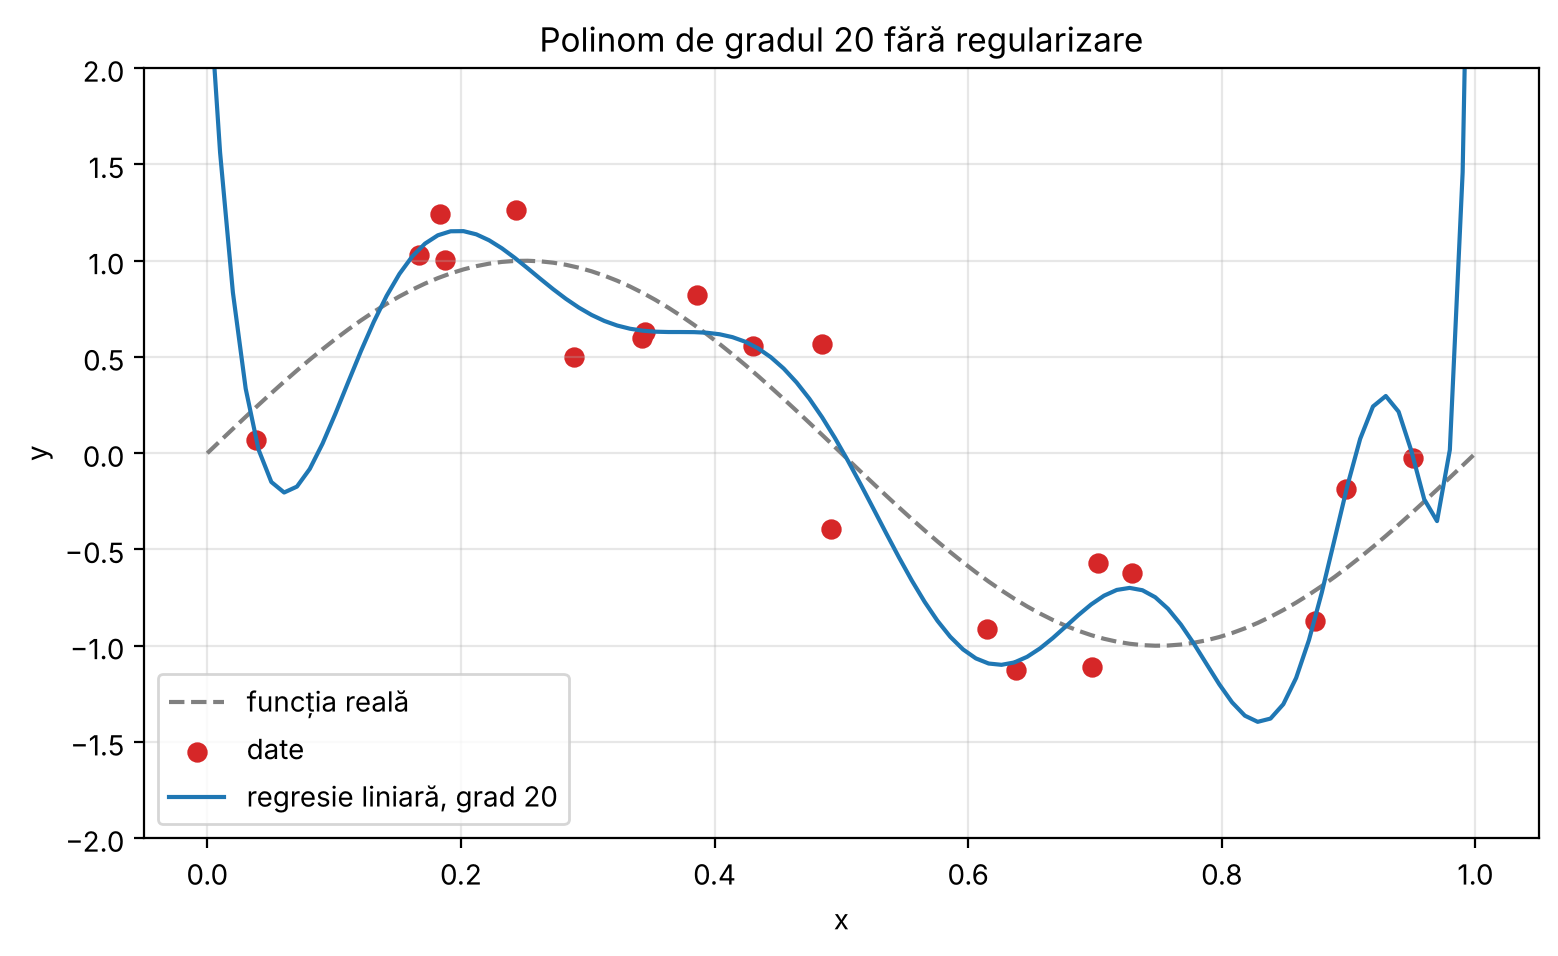

Predicții în intervalul [-1.4, 4.9] (axa y tăiată la [-2, 2])


In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

degree = 20
pf = PolynomialFeatures(degree)
lr = LinearRegression()

X_data = data[['x']]                      # DataFrame cu o coloană (matrice 2D)
Y_data = data['y']

X_poly = pf.fit_transform(X_data)
lr = lr.fit(X_poly, Y_data)

X_real_poly = pf.transform(pd.DataFrame({'x': X_real}))
Y_pred = lr.predict(X_real_poly)

plt.figure(figsize=(9, 5))
plt.plot(X_real, Y_real, ls='--', color='gray', label='funcția reală')
plt.scatter(X_data, Y_data, color='tab:red', s=40, label='date')
plt.plot(X_real, Y_pred, color='tab:blue', label='regresie liniară, grad 20')
plt.ylim(-2, 2)
plt.xlabel('x'); plt.ylabel('y'); plt.title('Polinom de gradul 20 fără regularizare'); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(f'Predicții în intervalul [{Y_pred.min():.1f}, {Y_pred.max():.1f}] (axa y tăiată la [-2, 2])')

**Observație.** Un polinom de gradul 20 are 21 de coeficienți, iar noi avem doar 20 de puncte – modelul poate trece prin (aproape) toate punctele. Curba oscilează puternic între puncte și la margini (predicții până la ~4.9), departe de funcția reală $\sin(2\pi x)$ – exemplu clasic de **supraadaptare**: eroare mică pe datele de antrenare, dar generalizare foarte proastă.

## Întrebare 3

* Efectuați regresia pe baza datelor cu caracteristici polinomiale utilizând regresia Ridge ($\alpha$=0,001) și regresia Lasso ($\alpha$=0,0001). 
* Reprezentați grafic rezultatele, așa cum s-a făcut la întrebarea 1. 
* De asemenea, reprezentați grafic magnitudinea coeficienților obținuți din aceste regresii și comparați-i cu cei obținuți din regresia liniară din întrebarea anterioară. Coeficienții regresiei liniare vor necesita probabil un grafic separat (sau propria axă y) din cauza magnitudinii lor mari. 

Ce vă spune magnitudinea comparativ mare a datelor cu privire la rolul regularizării?

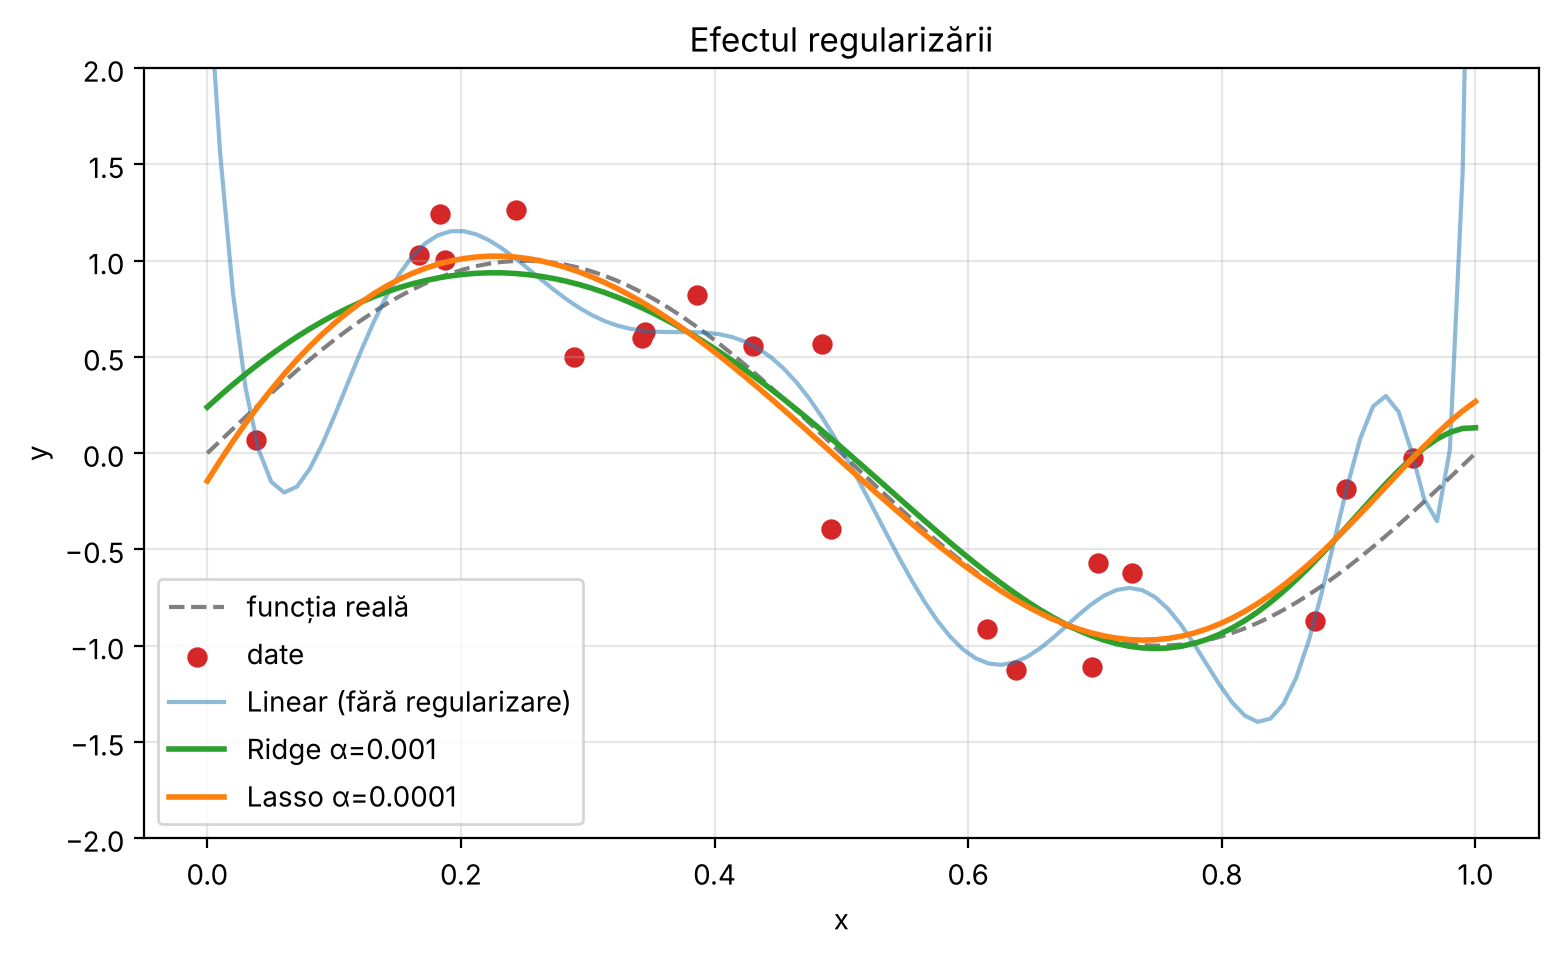

Linear : MSE față de funcția reală = 0.4406
Ridge  : MSE față de funcția reală = 0.0138
Lasso  : MSE față de funcția reală = 0.0116


In [4]:
from sklearn.linear_model import Ridge, Lasso

rr = Ridge(alpha=0.001).fit(X_poly, Y_data)
Y_pred_rr = rr.predict(X_real_poly)

lassor = Lasso(alpha=0.0001, max_iter=100000).fit(X_poly, Y_data)
Y_pred_lr = lassor.predict(X_real_poly)

plt.figure(figsize=(9, 5))
plt.plot(X_real, Y_real, ls='--', color='gray', label='funcția reală')
plt.scatter(X_data, Y_data, color='tab:red', s=40, label='date')
plt.plot(X_real, Y_pred, color='tab:blue', alpha=.5, label='Linear (fără regularizare)')
plt.plot(X_real, Y_pred_rr, color='tab:green', lw=2, label='Ridge α=0.001')
plt.plot(X_real, Y_pred_lr, color='tab:orange', lw=2, label='Lasso α=0.0001')
plt.ylim(-2, 2)
plt.xlabel('x'); plt.ylabel('y'); plt.title('Efectul regularizării'); plt.legend(); plt.grid(alpha=.3)
plt.show()

from sklearn.metrics import mean_squared_error
for name, yp in [('Linear', Y_pred), ('Ridge', Y_pred_rr), ('Lasso', Y_pred_lr)]:
    print(f'{name:7s}: MSE față de funcția reală = {mean_squared_error(Y_real, yp):.4f}')

putere x,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
linear regression,-3.52e-07,-115,1.61e+03,-9.08e+03,2.32e+04,-2.09e+04,-1.09e+04,1.54e+04,1.69e+04,-105,...,-1.56e+04,-5.22e+03,7.53e+03,1.46e+04,1.26e+04,3e+03,-8.71e+03,-1.53e+04,-9.4e+03,1.51e+04
ridge regression,0,6.07,-12.4,-4.07,2.31,4.43,4.14,2.88,1.48,0.308,...,-1.01,-1.2,-1.18,-1.02,-0.763,-0.468,-0.165,0.123,0.382,0.604
lasso regression,0,10.7,-25.4,0,17.5,0,0,-0,-0,-0,...,-1.31,-0,-0,-0,-0,-0,0,0,0,0


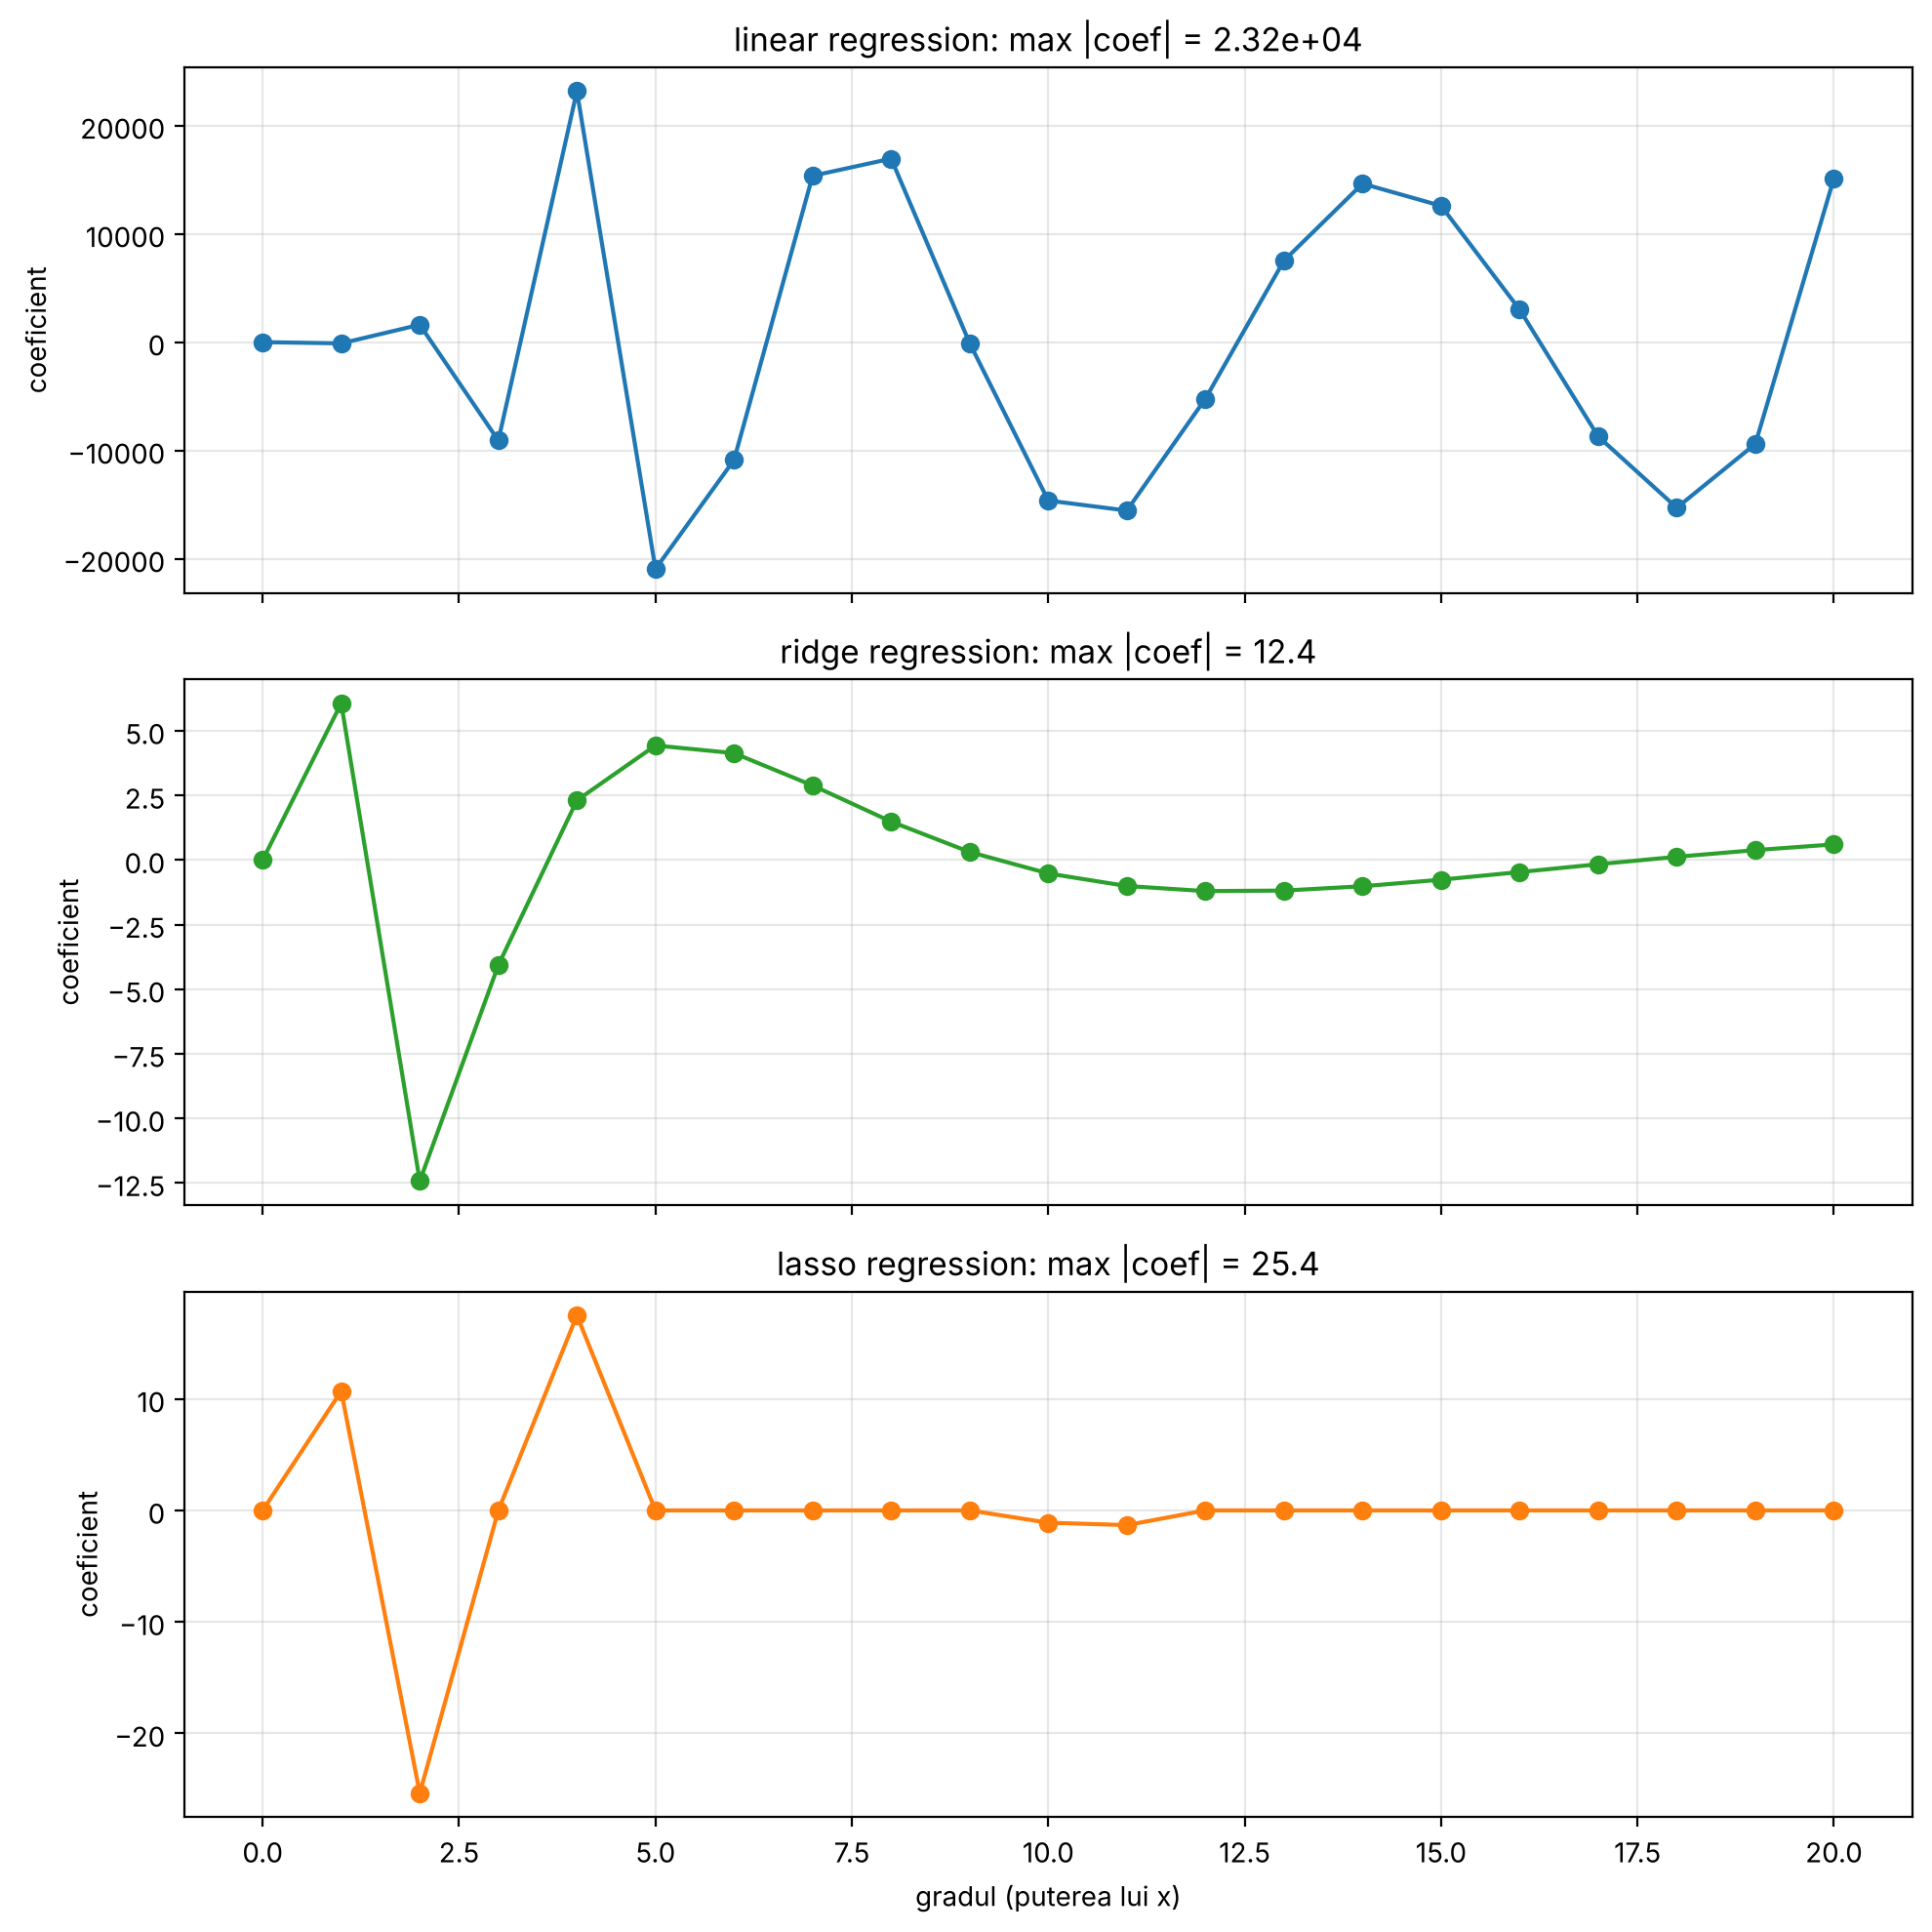

Coeficienți Lasso diferiți de zero: 5 din 21


In [5]:
coefficients = pd.DataFrame({'linear regression': lr.coef_,
                             'ridge regression': rr.coef_,
                             'lasso regression': lassor.coef_})
coefficients.index.name = 'putere x'
pd.options.display.float_format = '{:,.3g}'.format
display(coefficients.T)

fig, axList = plt.subplots(nrows=3, ncols=1, figsize=(10, 10), sharex=True)
for ax, col, color in zip(axList, coefficients.columns, ['tab:blue', 'tab:green', 'tab:orange']):
    ax.plot(coefficients[col], marker='o', color=color)
    ax.set_title(f'{col}: max |coef| = {coefficients[col].abs().max():,.3g}')
    ax.set_ylabel('coeficient'); ax.grid(alpha=.3)
axList[-1].set_xlabel('gradul (puterea lui x)')
plt.tight_layout(); plt.show()

print('Coeficienți Lasso diferiți de zero:', (lassor.coef_ != 0).sum(), 'din', len(lassor.coef_))

**Concluzii.**

- Ridge și Lasso produc curbe netede, foarte apropiate de $\sin(2\pi x)$: MSE față de funcția reală scade de la **0.44** (fără regularizare) la **0.014** (Ridge) și **0.012** (Lasso).
- **Magnitudinea coeficienților:** regresia liniară simplă are coeficienți de ordinul **10⁴** (până la ~2.3·10⁴), cu semne alternante – termenii mari se compensează reciproc doar pe punctele de antrenare. Ridge îi reduce la valori de ordinul unităților (|coef| ≤ ~12), iar Lasso păstrează doar **5 coeficienți nenuli din 21** (selecție de caracteristici).
- **Rolul regularizării:** penalizarea mărimii coeficienților (L2 – Ridge, L1 – Lasso) adaugă la funcția de cost un termen $\alpha\sum w_j^2$ sau $\alpha\sum |w_j|$. Astfel modelul nu poate folosi coeficienți uriași pentru a „memora” zgomotul; complexitatea efectivă scade, varianța scade, iar generalizarea se îmbunătățește. Coeficienții mari sunt un semn tipic de supraadaptare.

## Întrebarea 4

Pentru întrebările rămase, vom lucra cu [setul de date](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) din lecția trecută, care se bazează pe prețurile locuințelor din Ames, Iowa. Există un număr mare de caracteristici - a se vedea exercițiile din săptămâna a treia pentru o discuție despre aceste caracteristici.

Pentru a începe:

* Importați datele cu Pandas, eliminați orice valori nule și o codificare fierbinte a categoriilor. Pot fi utilizate fie codificatoarele de caracteristici Scikit-learn, fie metoda Pandas `get_dummies`.
* Împărțiți datele în seturi de instruire și de testare. 
* Transformarea logaritmică a caracteristicilor distorsionate. 
* Se poate încerca scalarea, deși poate fi interesant să se vadă cât de bine funcționează regularizarea fără scalarea caracteristicilor.

In [6]:
# 'None' din fișier înseamnă absența elementului (ex. nu există alee) -> o păstrăm ca categorie
data = pd.read_csv('Ames_Housing_Sales.csv', keep_default_na=False, na_values=[''])
print('Forma inițială:', data.shape)
data = data.dropna()                       # eliminăm eventualele valori nule rămase
print('După dropna  :', data.shape)

Forma inițială: (1379, 80)
După dropna  : (1379, 80)


Creați o listă de date categoriale și codificați one-hot. Pandas one-hot encoder (`get_dummies`) funcționează bine cu date care sunt definite ca fiind categoriale.

In [7]:
# Lista coloanelor categoriale (text)
one_hot_encode_cols = data.columns[~data.dtypes.apply(pd.api.types.is_numeric_dtype)].tolist()
print('Coloane categoriale:', len(one_hot_encode_cols))
num_cols = [col for col in data.columns if col not in one_hot_encode_cols]   # coloanele numerice inițiale

# Ne asigurăm că sunt de tip 'category' și facem one-hot cu Pandas
data[one_hot_encode_cols] = data[one_hot_encode_cols].astype('category')
data = pd.get_dummies(data, columns=one_hot_encode_cols, drop_first=True, dtype=float)
print('Forma după one-hot:', data.shape)

Coloane categoriale: 43
Forma după one-hot: (1379, 252)


Apoi, împărțiți datele în seturi de date de instruire și de testare.

In [8]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.3, random_state=RANDOM_STATE)
print('train:', train.shape, '| test:', test.shape)

train: (965, 252) | test: (414, 252)


Există o serie de coloane care au caracteristici înclinate - li se poate aplica o transformare logaritmică. Rețineți că aceasta include `SalePrice`, predictorul nostru. Cu toate acestea, să o păstrăm așa cum este.

In [9]:
# Doar coloanele numerice inițiale (coloanele one-hot conțin 0/1 și nu se transformă)
float_cols = num_cols

skew_limit = 0.75
skew_vals = train[float_cols].skew()          # oblicitatea calculată pe train

skew_cols = (skew_vals
             .sort_values(ascending=False)
             .to_frame()
             .rename(columns={0: 'Skew'})
             .query('abs(Skew) > {}'.format(skew_limit)))
pd.options.display.float_format = '{:,.3f}'.format
skew_cols

,Skew
MiscVal,26.915
PoolArea,15.778
LotArea,11.502
LowQualFinSF,11.211
3SsnPorch,10.151
KitchenAbvGr,5.498
ScreenPorch,4.600
BsmtFinSF2,4.466
BsmtHalfBath,3.882
EnclosedPorch,3.218


Transformați toate coloanele în care deviația este mai mare de 0,75, cu excepția „SalePrice”.

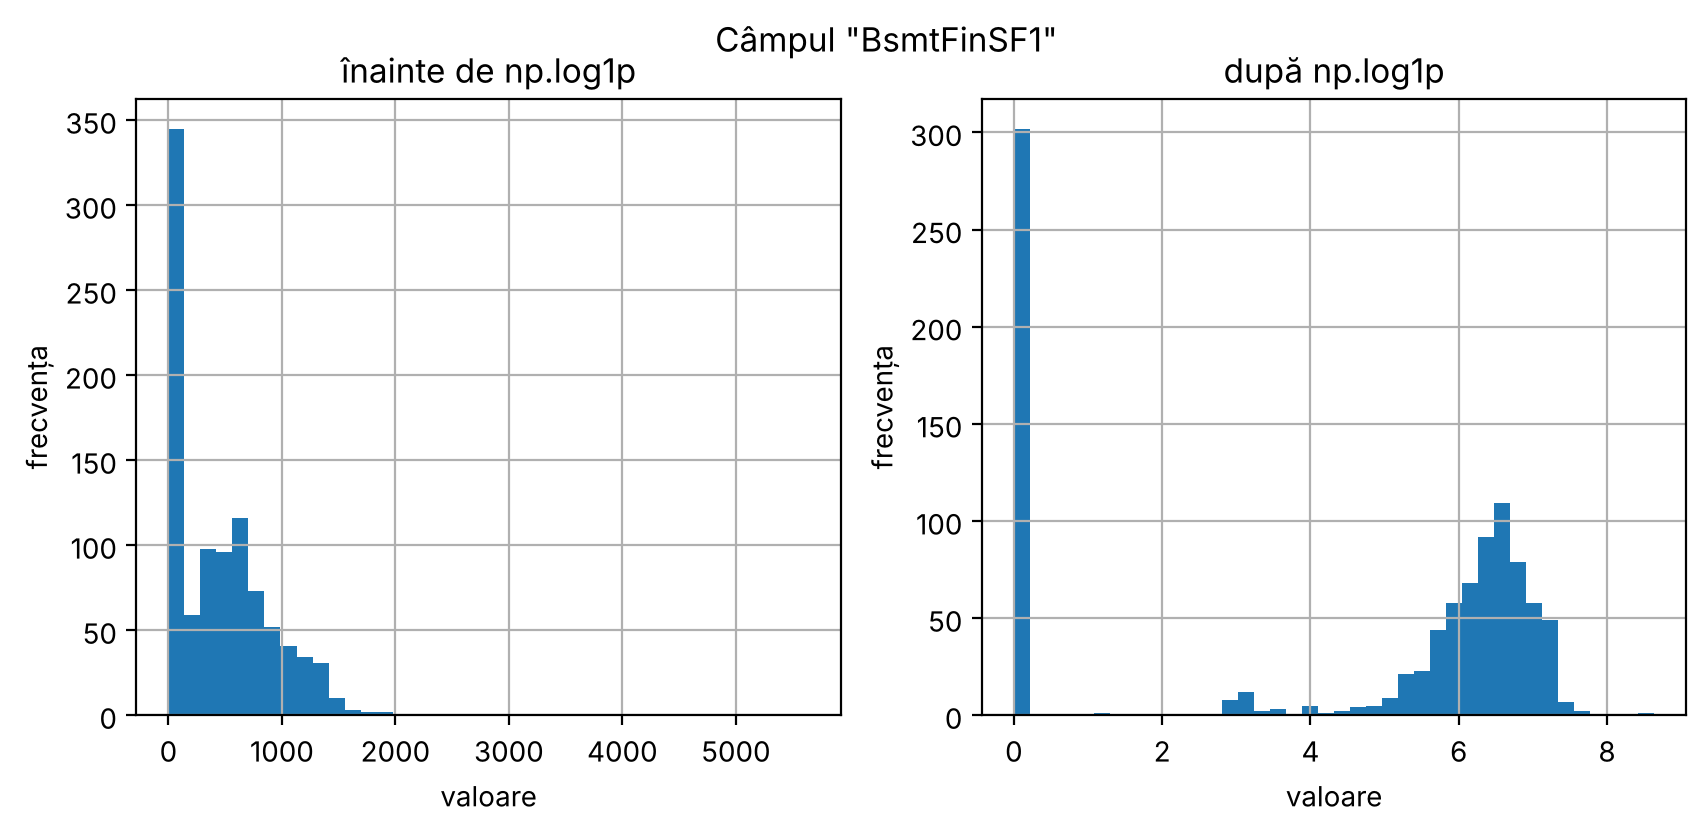

Coloane transformate: ['MiscVal', 'PoolArea', 'LotArea', 'LowQualFinSF', '3SsnPorch', 'KitchenAbvGr', 'ScreenPorch', 'BsmtFinSF2', 'BsmtHalfBath', 'EnclosedPorch', 'LotFrontage', 'MasVnrArea', 'OpenPorchSF', 'BsmtFinSF1', 'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'MSSubClass', 'WoodDeckSF', 'OverallCond', 'BsmtUnfSF', 'GarageArea', '2ndFlrSF']


In [10]:
# Exemplu vizual pentru o coloană
field = 'BsmtFinSF1'
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4))
train[field].hist(ax=ax_before, bins=40)
train[field].apply(np.log1p).hist(ax=ax_after, bins=40)
ax_before.set(title='înainte de np.log1p', ylabel='frecvența', xlabel='valoare')
ax_after.set(title='după np.log1p', ylabel='frecvența', xlabel='valoare')
fig.suptitle(f'Câmpul "{field}"'); plt.show()

# Transformăm toate coloanele cu skew > 0.75, cu excepția SalePrice, identic pe train și test
for col in skew_cols.index.tolist():
    if col == 'SalePrice':
        continue
    train[col] = np.log1p(train[col].clip(lower=0))
    test[col] = test[col].apply(lambda v: np.log1p(max(v, 0)))
print('Coloane transformate:', [c_ for c_ in skew_cols.index if c_ != 'SalePrice'])

Separate features from predictor.

In [11]:
feature_cols = [x for x in train.columns if x != 'SalePrice']
X_train = train[feature_cols]
y_train = train['SalePrice']

X_test = test[feature_cols]
y_test = test['SalePrice']
print(X_train.shape, X_test.shape)

(965, 251) (414, 251)


## Întrebare 5

* Scrieți o funcție **`rmse`** care primește valorile de adevăr și predicție și returnează eroarea medie pătratică. Utilizați funcția `mean_squared_error` de la sklearn.  


In [12]:
from sklearn.metrics import mean_squared_error

def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

* Adaptați un model de regresie liniară de bază
* tipăriți eroarea medie pătratică pentru acest model
* reprezentați grafic prețul de vânzare previzionat față de cel real pe baza modelului.  

RMSE regresie liniară (test): 78,634 $
RMSE regresie liniară (train): 20,200 $


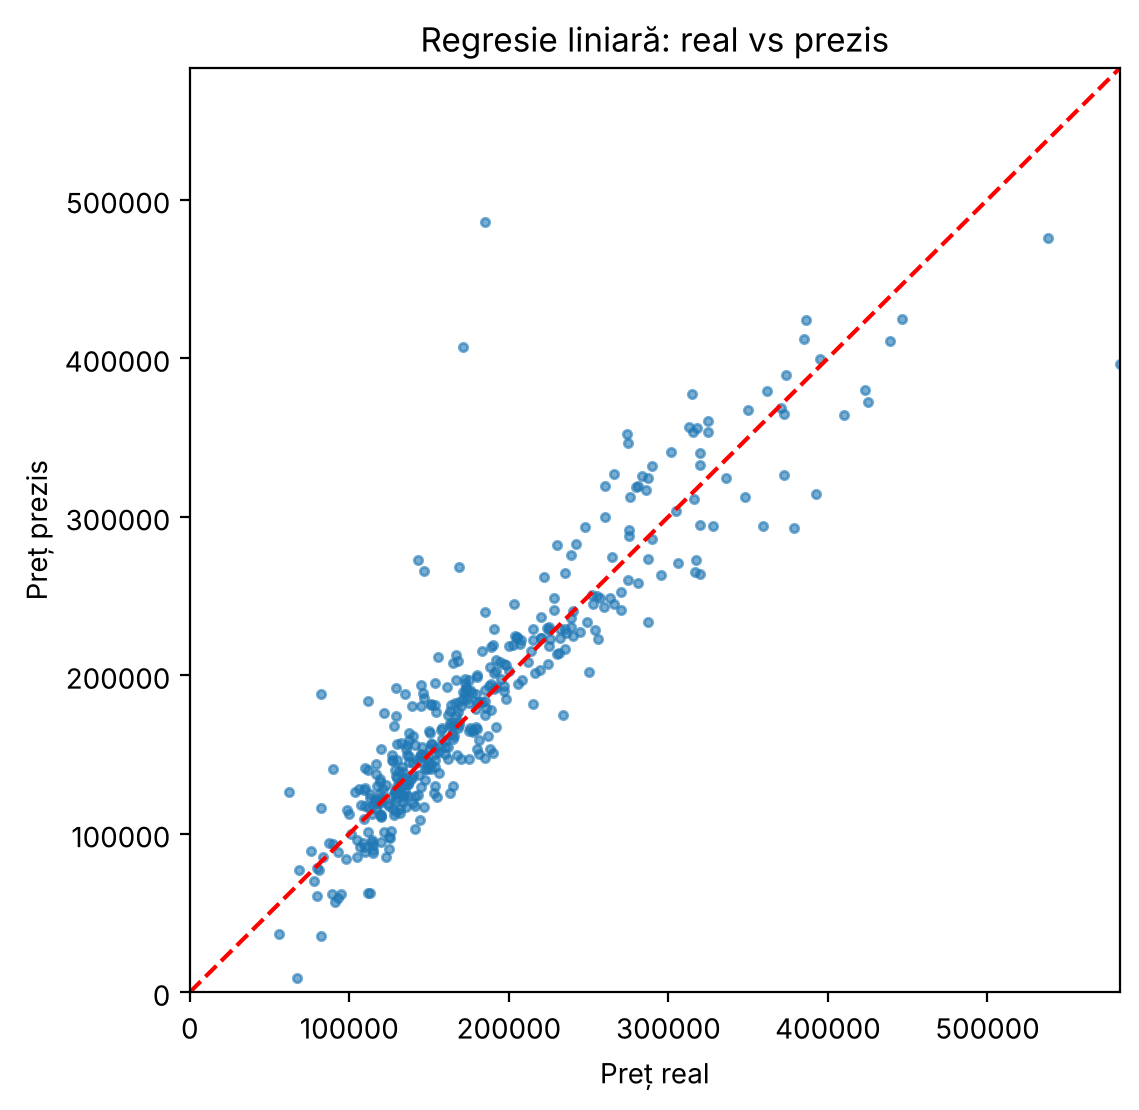

In [13]:
from sklearn.linear_model import LinearRegression

linearRegression = LinearRegression().fit(X_train, y_train)
linearRegression_rmse = rmse(y_test, linearRegression.predict(X_test))
print(f'RMSE regresie liniară (test): {linearRegression_rmse:,.0f} $')
print(f'RMSE regresie liniară (train): {rmse(y_train, linearRegression.predict(X_train)):,.0f} $')

def plot_pred(y_true, y_pred, title):
    f = plt.figure(figsize=(6, 6))
    ax = plt.axes()
    ax.plot(y_true, y_pred, marker='o', ls='', ms=3.0, alpha=.6)
    lim = (0, y_true.max())
    ax.set(xlabel='Preț real', ylabel='Preț prezis', xlim=lim, ylim=lim, title=title)
    ax.plot(lim, lim, 'r--')
    ax.ticklabel_format(style='plain')
    plt.show()

plot_pred(y_test, linearRegression.predict(X_test), 'Regresie liniară: real vs prezis')

**Observație.** Regresia liniară fără regularizare pe 251 de caracteristici (cu one-hot) are RMSE pe test ~78 600 $, față de doar ~20 200 $ pe train – aceeași supraadaptare ca în laboratorul 3. Pe grafic se văd câteva predicții foarte departe de diagonală.

## Întrebarea 6

Regresia Ridge utilizează normalizarea L2 pentru a reduce magnitudinea coeficienților. Acest lucru poate fi util în situații în care există o varianță ridicată. Funcțiile de regularizare din Scikit-learn conțin fiecare versiuni care au validarea încrucișată încorporată.

* Adaptați un model Ridge regulat (nevalidat încrucișat) la o gamă de valori $\alpha$ și reprezentați grafic RMSE utilizând funcția de eroare validată încrucișat pe care ați creat-o mai sus.
* Utilizați $$[0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]$$ ca interval de alphas.
* Apoi repetați ajustarea modelelor Ridge folosind gama de valori $\alpha$ din secțiunea anterioară. Comparați rezultatele.

,RMSE CV (train),RMSE test
alpha,,
0.005000,"35,375","42,164"
0.050000,"33,998","40,924"
0.100000,"33,287","39,781"
0.300000,"32,285","37,188"
1.000000,"31,595","34,395"
3.000000,"30,992","32,890"
5.000000,"30,759","32,495"
10.000000,"30,678","32,206"
15.000000,"30,831","32,167"


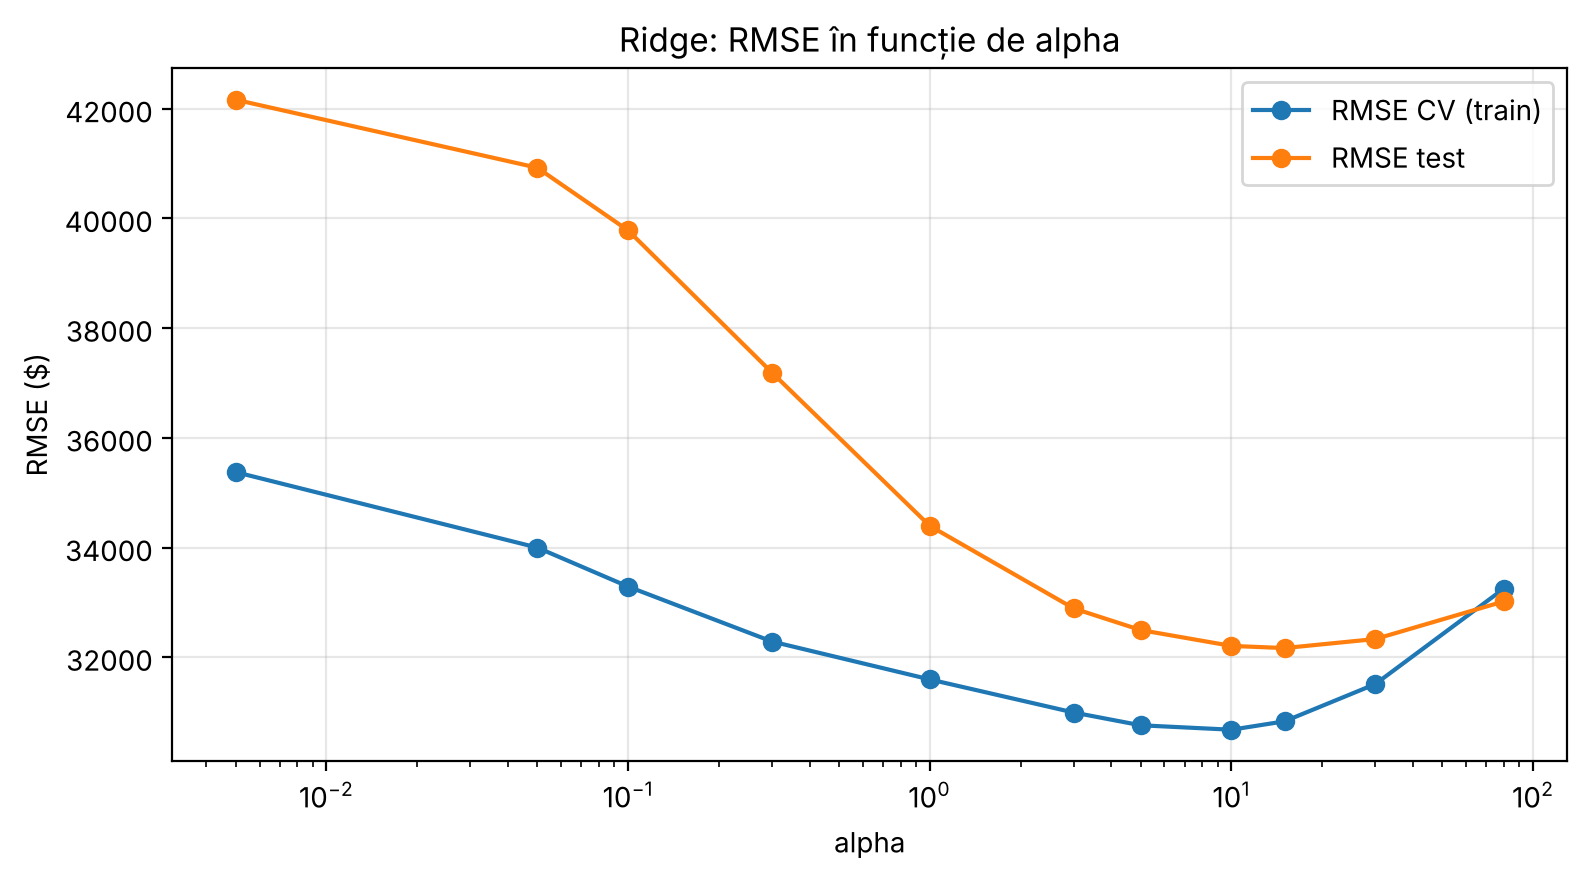

Cel mai bun alpha după CV: 10.0


In [14]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import cross_val_score, KFold

alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]
kf = KFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

ridge_rows = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    # eroare validată încrucișat pe train (RMSE pe fiecare fold)
    cv_rmse = np.sqrt(-cross_val_score(ridge, X_train, y_train, cv=kf, scoring='neg_mean_squared_error'))
    ridge.fit(X_train, y_train)
    ridge_rows.append({'alpha': alpha, 'RMSE CV (train)': cv_rmse.mean(), 'RMSE test': rmse(y_test, ridge.predict(X_test))})

ridge_df = pd.DataFrame(ridge_rows).set_index('alpha')
display(ridge_df.style.format('{:,.0f}'))

ax = ridge_df.plot(marker='o', logx=True, figsize=(9, 4.5))
ax.set(xlabel='alpha', ylabel='RMSE ($)', title='Ridge: RMSE în funcție de alpha'); ax.grid(alpha=.3)
plt.show()
print('Cel mai bun alpha după CV:', ridge_df['RMSE CV (train)'].idxmin())

Acum, pentru metoda `RidgeCV`. Din păcate, nu este posibil să obținem valorile alfa pentru modelele care nu au fost selectate. Valorile erorilor și valorile $\alpha$ rezultate sunt foarte asemănătoare cu cele obținute mai sus.

In [15]:
ridgeCV = RidgeCV(alphas=alphas, cv=4).fit(X_train, y_train)
ridgeCV_rmse = rmse(y_test, ridgeCV.predict(X_test))

print(f'RidgeCV: alpha optim = {ridgeCV.alpha_}, RMSE test = {ridgeCV_rmse:,.0f} $')

RidgeCV: alpha optim = 10.0, RMSE test = 32,206 $


**Concluzii.** Cu creșterea lui α, RMSE scade (atât CV pe train, cât și pe test) până la **α ≈ 10**, apoi crește din nou (la α=80 regularizarea e prea puternică – subadaptare). Atât căutarea manuală cu validare încrucișată, cât și `RidgeCV` aleg **α = 10**, cu RMSE test ≈ **32 200 $** – de aproape 2.5 ori mai bun decât regresia liniară fără regularizare (~78 600 $). Rezultatele celor două metode coincid.

## Întrebarea 7


La fel ca funcția `RidgeCV`, există și o funcție `LassoCV` care utilizează o funcție de regularizare L1 și validarea încrucișată. Regularizarea L1 va micșora selectiv anumiți coeficienți, efectuând efectiv eliminarea caracteristicilor.

Funcția `LassoCV` nu permite setarea funcției de scor. Cu toate acestea, funcția de eroare personalizată (`rmse`) creată mai sus poate fi utilizată pentru a evalua eroarea modelului final.

În mod similar, există și o funcție elastic net cu validare încrucișată, `ElasticNetCV`, care este o combinație de regularizare L2 și L1.

* Potriviți un model Lasso utilizând validarea încrucișată și determinați valoarea optimă pentru $\alpha$ și RMSE utilizând funcția creată mai sus. Rețineți că magnitudinea lui $\alpha$ poate fi diferită de cea a modelului Ridge.
* Repetați operația cu modelul de plasă elastică.
* Comparați rezultatele prin tabel și/sau grafic.

Utilizați următoarele alphas:

`[1e-5, 5e-5, 0.0001, 0.0005]`

In [16]:
from sklearn.linear_model import LassoCV

alphas2 = np.array([1e-5, 5e-5, 0.0001, 0.0005])

lassoCV = LassoCV(alphas=alphas2, max_iter=50000, cv=3).fit(X_train, y_train)
lassoCV_rmse = rmse(y_test, lassoCV.predict(X_test))

print(f'LassoCV: alpha optim = {lassoCV.alpha_}, RMSE test = {lassoCV_rmse:,.0f} $')

LassoCV: alpha optim = 0.0005, RMSE test = 89,886 $


Putem determina câte dintre aceste caracteristici rămân diferite de zero.

In [17]:
print('Din {} coeficienți, {} sunt diferiți de zero cu Lasso.'.format(
    len(lassoCV.coef_), len(lassoCV.coef_.nonzero()[0])))

Din 251 coeficienți, 240 sunt diferiți de zero cu Lasso.


Încercați acum plasa elastică, cu aceleași alphas ca în Lasso, și l1_ratios între 0,1 și 0,9

In [18]:
from sklearn.linear_model import ElasticNetCV

l1_ratios = np.linspace(0.1, 0.9, 9)

elasticNetCV = ElasticNetCV(alphas=alphas2, l1_ratio=l1_ratios, max_iter=10000, cv=3).fit(X_train, y_train)
elasticNetCV_rmse = rmse(y_test, elasticNetCV.predict(X_test))

print(f'ElasticNetCV: alpha = {elasticNetCV.alpha_}, l1_ratio = {elasticNetCV.l1_ratio_:.1f}, RMSE test = {elasticNetCV_rmse:,.0f} $')
print('Coeficienți diferiți de zero:', len(elasticNetCV.coef_.nonzero()[0]), 'din', len(elasticNetCV.coef_))

ElasticNetCV: alpha = 0.0005, l1_ratio = 0.1, RMSE test = 36,243 $
Coeficienți diferiți de zero: 241 din 251


Compararea calculului RMSE din toate modelele este cea mai ușoară într-un tabel.

,RMSE,alpha,coef. nenuli
Linear,"78,634",nan,247
Ridge,"32,206",10,241
Lasso,"89,886",0.0005,240
ElasticNet,"36,243",0.0005,241


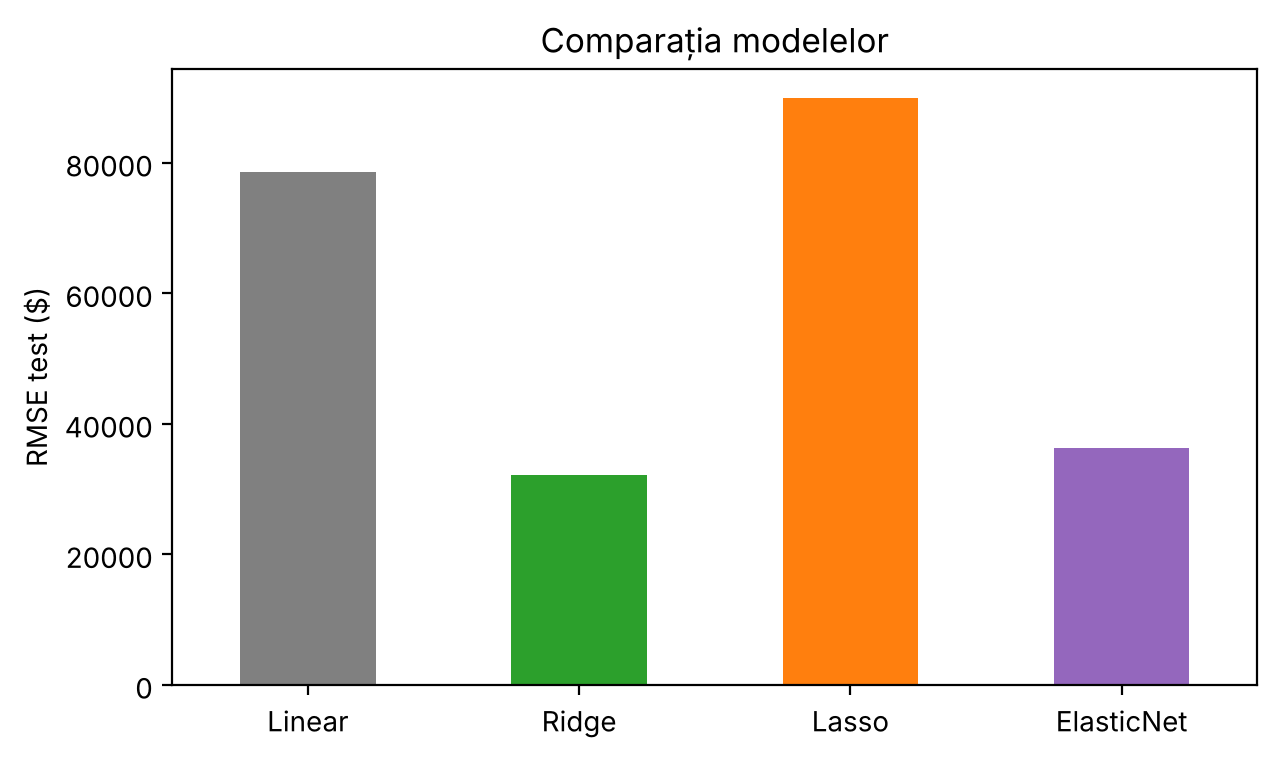

In [19]:
rmse_vals = [linearRegression_rmse, ridgeCV_rmse, lassoCV_rmse, elasticNetCV_rmse]
labels = ['Linear', 'Ridge', 'Lasso', 'ElasticNet']

rmse_df = pd.Series(rmse_vals, index=labels).to_frame()
rmse_df.rename(columns={0: 'RMSE'}, inplace=True)
rmse_df['alpha'] = [np.nan, ridgeCV.alpha_, lassoCV.alpha_, elasticNetCV.alpha_]
rmse_df['coef. nenuli'] = [np.count_nonzero(m.coef_) for m in [linearRegression, ridgeCV, lassoCV, elasticNetCV]]
display(rmse_df.style.format({'RMSE': '{:,.0f}', 'alpha': '{:g}'}))

ax = rmse_df['RMSE'].plot.bar(figsize=(7, 4), rot=0, color=['gray', 'tab:green', 'tab:orange', 'tab:purple'])
ax.set(ylabel='RMSE test ($)', title='Comparația modelelor'); plt.show()

Putem, de asemenea, să realizăm un grafic al prețurilor reale și previzionate ale locuințelor, la fel ca înainte.

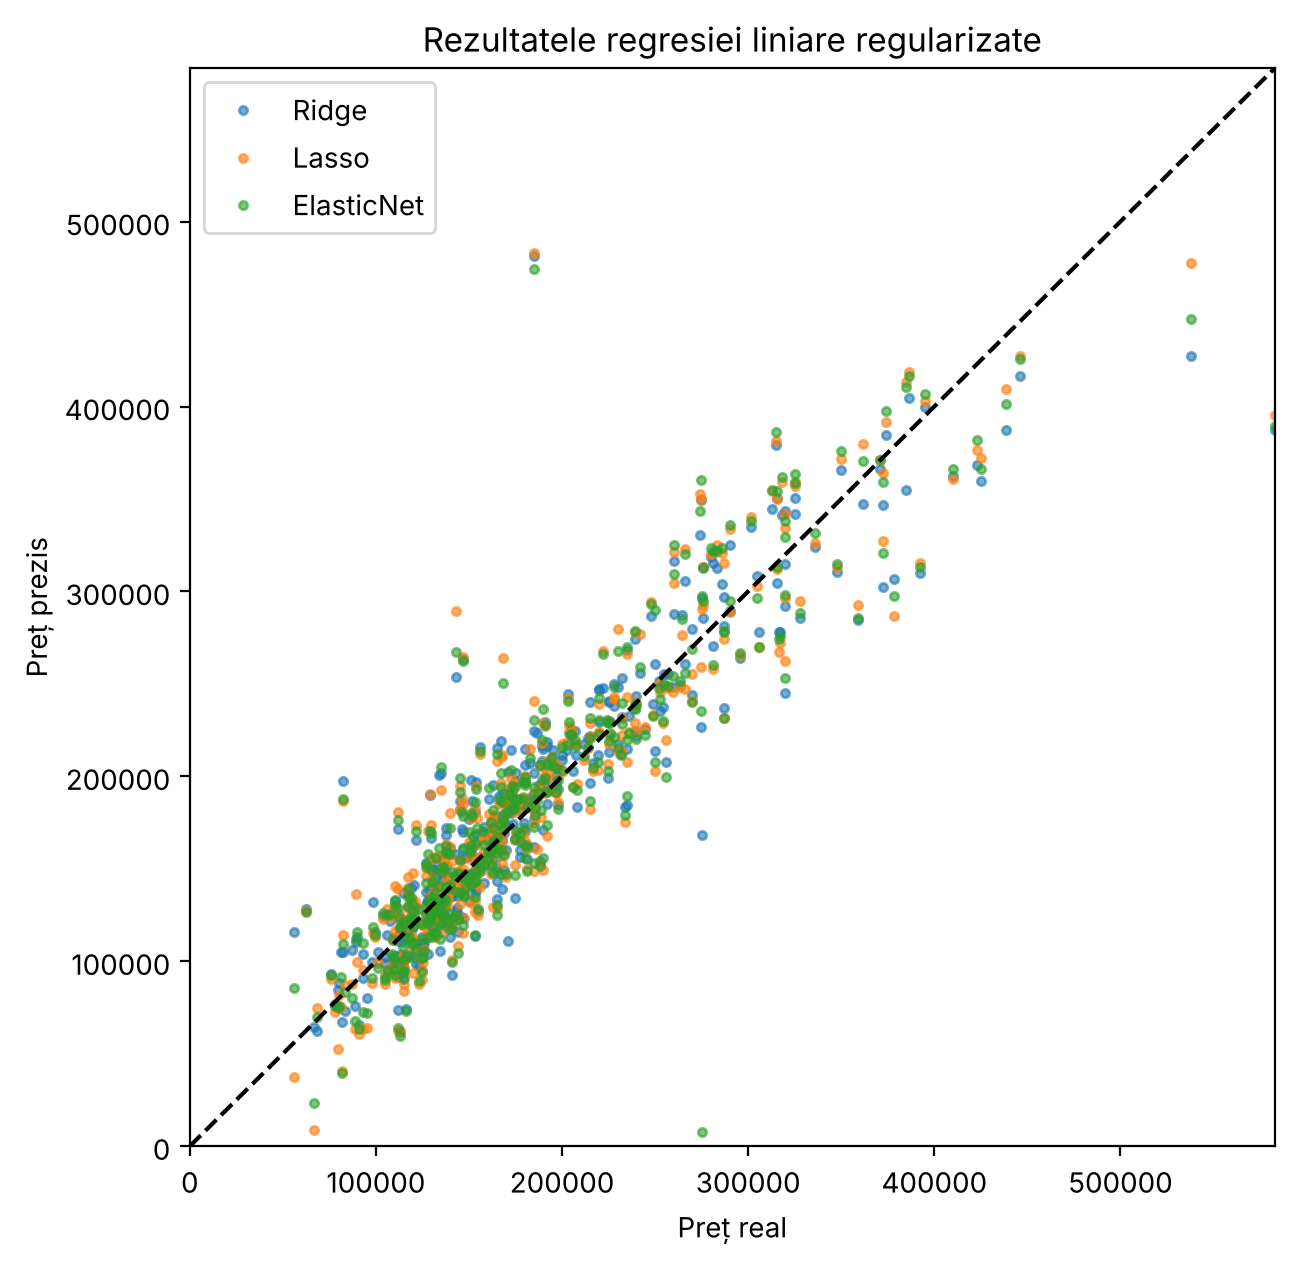

In [20]:
f = plt.figure(figsize=(7, 7))
ax = plt.axes()

labels_m = ['Ridge', 'Lasso', 'ElasticNet']
models = [ridgeCV, lassoCV, elasticNetCV]

for mod, lab in zip(models, labels_m):
    ax.plot(y_test, mod.predict(X_test), marker='o', ls='', ms=3.0, alpha=.6, label=lab)

lim = (0, y_test.max())
ax.plot(lim, lim, 'k--')
leg = plt.legend(frameon=True)
ax.set(xlabel='Preț real', ylabel='Preț prezis', xlim=lim, ylim=lim, title='Rezultatele regresiei liniare regularizate')
ax.ticklabel_format(style='plain')
plt.show()

#### Suplimentar: Lasso cu valori alpha potrivite scării datelor
Valorile alpha din enunț sunt foarte mici pentru o țintă în dolari (nescalată), deci Lasso aproape că nu regularizează. Verificăm ce se întâmplă cu alpha mai mari.

In [21]:
lassoCV_big = LassoCV(alphas=[10, 30, 100, 300, 1000], max_iter=100000, cv=3).fit(X_train, y_train)
print(f'LassoCV (alpha mari): alpha optim = {lassoCV_big.alpha_}, RMSE test = {rmse(y_test, lassoCV_big.predict(X_test)):,.0f} $, '
      f'coeficienți nenuli = {np.count_nonzero(lassoCV_big.coef_)} din {len(lassoCV_big.coef_)}')

LassoCV (alpha mari): alpha optim = 100, RMSE test = 38,017 $, coeficienți nenuli = 111 din 251


**Concluzii.**

| Model | RMSE test | Observații |
|---|---|---|
| Linear | ~78 600 $ | supraadaptare |
| **Ridge (α=10)** | **~32 200 $** | cel mai bun |
| Lasso (α=0.0005) | ~89 900 $ | α prea mic → practic fără regularizare |
| ElasticNet (α=0.0005, l1_ratio=0.1) | ~36 200 $ | predominant L2 |

- Cu valorile α din enunț ([1e-5 … 5e-4]), Lasso este practic regresie liniară simplă (240 din 251 coeficienți nenuli) și nu converge bine pe date nescalate – α trebuie ales în raport cu scara țintei (aici dolari). Cu α mai mare (experimentul suplimentar, α=100) Lasso ajunge la RMSE ≈ 38 000 $ și **păstrează doar ~111 caracteristici** – exact selecția de caracteristici prin L1.
- ElasticNet alege l1_ratio = 0.1 (aproape Ridge), confirmând că pentru aceste date penalizarea L2 funcționează cel mai bine.
- Ridge dă cel mai mic RMSE: multe caracteristici corelate, fiecare cu o contribuție mică – L2 le micșorează pe toate în loc să elimine o parte dintre ele.

## Întrebarea 8

Să explorăm coborârea stochastică a gradientului în acest exercițiu.  
Reamintim că modelele liniare în general sunt sensibile la scalare.
Cu toate acestea, SGD este *foarte* sensibil la scalare.  
În plus, o valoare mare a ratei de învățare poate determina algoritmul să devieze, în timp ce o valoare prea mică poate dura prea mult până la convergență.

* Potriviți un model stochastic gradient descent fără o penalizare de regularizare (parametrul relevant este `penalty`).
* Ajustați acum modele stochastice de coborâre în gradient cu fiecare dintre cele trei penalizări (L2, L1, Elastic Net) folosind valorile parametrilor determinate prin validarea încrucișată de mai sus. 
* Nu scalați datele înainte de ajustarea modelului.  
* Comparați rezultatele cu cele obținute fără a utiliza coborârea stochastică în gradient.

In [22]:
from sklearn.linear_model import SGDRegressor

# Notă: în enunț apare SGDClassifier, dar ținta (SalePrice) este continuă, deci folosim SGDRegressor.
model_parameters_dict = {
    'Linear':     {'penalty': None},
    'Lasso':      {'penalty': 'l1', 'alpha': lassoCV.alpha_},
    'Ridge':      {'penalty': 'l2', 'alpha': ridgeCV.alpha_},
    'ElasticNet': {'penalty': 'elasticnet', 'alpha': elasticNetCV.alpha_, 'l1_ratio': elasticNetCV.l1_ratio_},
}

def safe_rmse(y_true, y_pred):
    # la divergență predicțiile pot deveni inf/NaN
    return rmse(y_true, y_pred) if np.all(np.isfinite(y_pred)) else np.inf

new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    SGD = SGDRegressor(max_iter=1000, random_state=RANDOM_STATE, **parameters)
    SGD.fit(X_train, y_train)
    new_rmses[modellabel] = safe_rmse(y_test, SGD.predict(X_test))

rmse_df['RMSE-SGD'] = pd.Series(new_rmses)
pd.options.display.float_format = '{:,.3e}'.format
display(rmse_df[['RMSE', 'RMSE-SGD']])

,RMSE,RMSE-SGD
Linear,7.863e+04,5.890e+15
Ridge,3.221e+04,4.939e+15
Lasso,8.989e+04,3.525e+14
ElasticNet,3.624e+04,6.618e+14


**Observație.** Erorile sunt de ordinul **10¹⁴–10¹⁵ $** – algoritmul SGD **divergent**. Caracteristicile nescalate au ordine de mărime foarte diferite (ani ~2000, suprafețe ~1000, dummy 0/1), iar rata de învățare implicită (`eta0=0.01`) este mult prea mare: fiecare pas „sare” peste minim și greutățile explodează.

Observați cât de mari sunt valorile erorii! Algoritmul este divergent. Acest lucru se poate datora faptului că scalarea și/sau rata de învățare sunt prea mari. Să ajustăm rata de învățare și să vedem ce se întâmplă.

* Introduceți `eta0=1e-7` la crearea instanței de `SGDClassifier`.
* Calculați din nou erorile pentru toate penalitățile și comparați.

In [23]:
new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    SGD = SGDRegressor(eta0=1e-7, max_iter=1000, random_state=RANDOM_STATE, **parameters)
    SGD.fit(X_train, y_train)
    new_rmses[modellabel] = safe_rmse(y_test, SGD.predict(X_test))

rmse_df['RMSE-SGD-learningrate'] = pd.Series(new_rmses)
pd.options.display.float_format = '{:,.0f}'.format
display(rmse_df[['RMSE', 'RMSE-SGD', 'RMSE-SGD-learningrate']])

,RMSE,RMSE-SGD,RMSE-SGD-learningrate
Linear,"78,634","5,890,380,855,718,348","74,750"
Ridge,"32,206","4,938,913,222,211,196","74,753"
Lasso,"89,886","352,455,949,469,891","74,750"
ElasticNet,"36,243","661,787,056,332,391","74,750"


**Observație.** Cu `eta0=1e-7` algoritmul nu mai diverge: RMSE ≈ **74 750 $** pentru toate penalizările. Totuși rezultatul este mai slab decât soluțiile regularizate exacte (Ridge ~32 000 $): pașii sunt atât de mici încât SGD nu ajunge la minim în numărul dat de iterații, iar penalizările (cu α mici) aproape nu contează – toate modelele dau practic același rezultat.

Acum să ne scalăm datele de antrenament și să încercăm din nou.

* Adaptați un `MinMaxScaler` la `X_train` și creați o variabilă `X_train_scaled`.
* Folosind scala, transformați `X_test` și creați o variabilă `X_test_scaled`. 
* Aplicați-le aceleași versiuni ale SGD și comparați rezultatele. De data aceasta nu introduceți un eta0.

In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    SGD = SGDRegressor(max_iter=5000, random_state=RANDOM_STATE, **parameters)
    SGD.fit(X_train_scaled, y_train)
    new_rmses[modellabel] = safe_rmse(y_test, SGD.predict(X_test_scaled))

rmse_df['RMSE-SGD-scaled'] = pd.Series(new_rmses)
display(rmse_df[['RMSE', 'RMSE-SGD', 'RMSE-SGD-learningrate', 'RMSE-SGD-scaled']])

,RMSE,RMSE-SGD,RMSE-SGD-learningrate,RMSE-SGD-scaled
Linear,"78,634","5,890,380,855,718,348","74,750","32,675"
Ridge,"32,206","4,938,913,222,211,196","74,753","70,586"
Lasso,"89,886","352,455,949,469,891","74,750","32,675"
ElasticNet,"36,243","661,787,056,332,391","74,750","32,643"


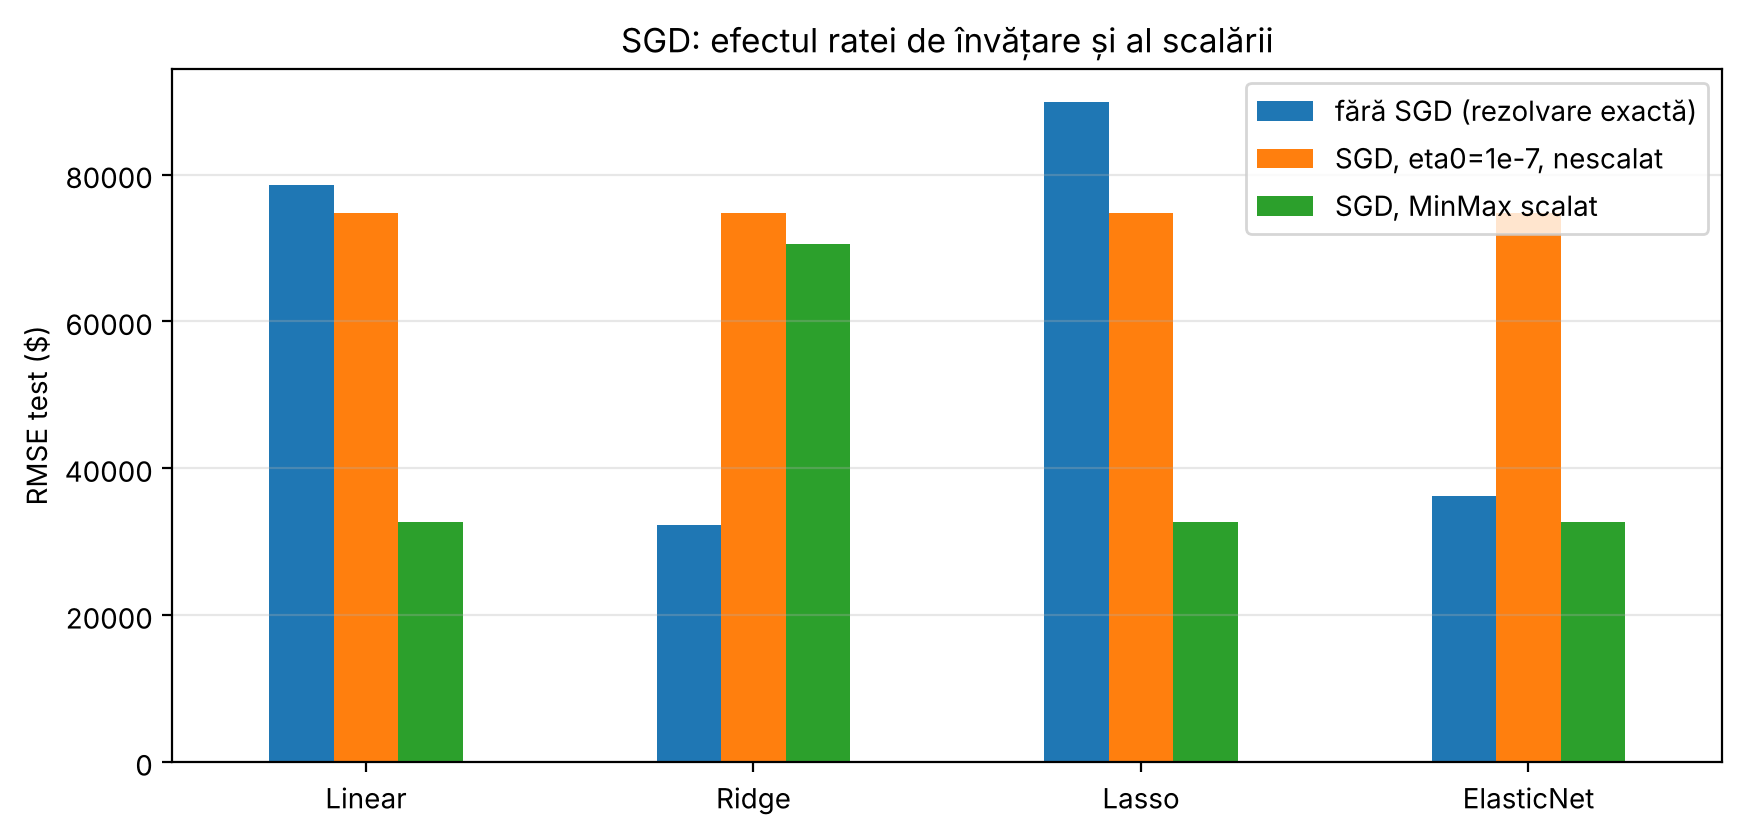

In [25]:
plot_df = rmse_df[['RMSE', 'RMSE-SGD-learningrate', 'RMSE-SGD-scaled']].rename(columns={
    'RMSE': 'fără SGD (rezolvare exactă)', 'RMSE-SGD-learningrate': 'SGD, eta0=1e-7, nescalat', 'RMSE-SGD-scaled': 'SGD, MinMax scalat'})
ax = plot_df.plot.bar(figsize=(10, 4.5), rot=0)
ax.set(ylabel='RMSE test ($)', title='SGD: efectul ratei de învățare și al scalării'); ax.grid(alpha=.3, axis='y')
plt.show()

**Concluzii.**

- După scalarea `MinMaxScaler` (toate caracteristicile în [0,1]), SGD converge cu rata de învățare implicită: **Linear, Lasso și ElasticNet ≈ 32 600 $** – la nivelul celui mai bun model exact (RidgeCV ~32 200 $) și mult mai bine decât OLS exact (~78 600 $). Opritul timpuriu al SGD acționează ca o regularizare implicită.
- **Ridge ≈ 70 600 $** – mai slab, deoarece în `SGDRegressor` parametrul `alpha` are altă semnificație: penalizarea se aplică la fiecare pas (∝ α·n față de `Ridge`), deci α=10 preluat de la `RidgeCV` este o regularizare mult prea puternică (subadaptare). α trebuie re-optimizat pentru SGD.
- **Lecția principală:** SGD este *foarte* sensibil la scalare și la rata de învățare – fără scalare diverge (10¹⁵ $), cu rată mică converge prea lent (~74 750 $), iar cu date scalate funcționează la fel de bine ca metodele exacte, fiind în plus potrivit pentru seturi de date foarte mari.